 Resonant Plasma Inverter Pipeline

EXECUTING RESO-ZCD SYSTEM SIMULATION AT f_sw = 25.0 kHz
True Ground-Truth Crossings (ms):  [ 0. 20. 40.]
Detected ZCD Timestamps (ms):     [ 0.1885898  20.17395879 40.22905896]
Sub-Sample Timing Jitter:         23.304 microseconds
Hard Switching Power Loss:        0.1250 W per MOSFET
ZVS Operating Power Loss:         0.03075900 W per MOSFET
Efficiency Factor:                Loss reduced by 4.1x


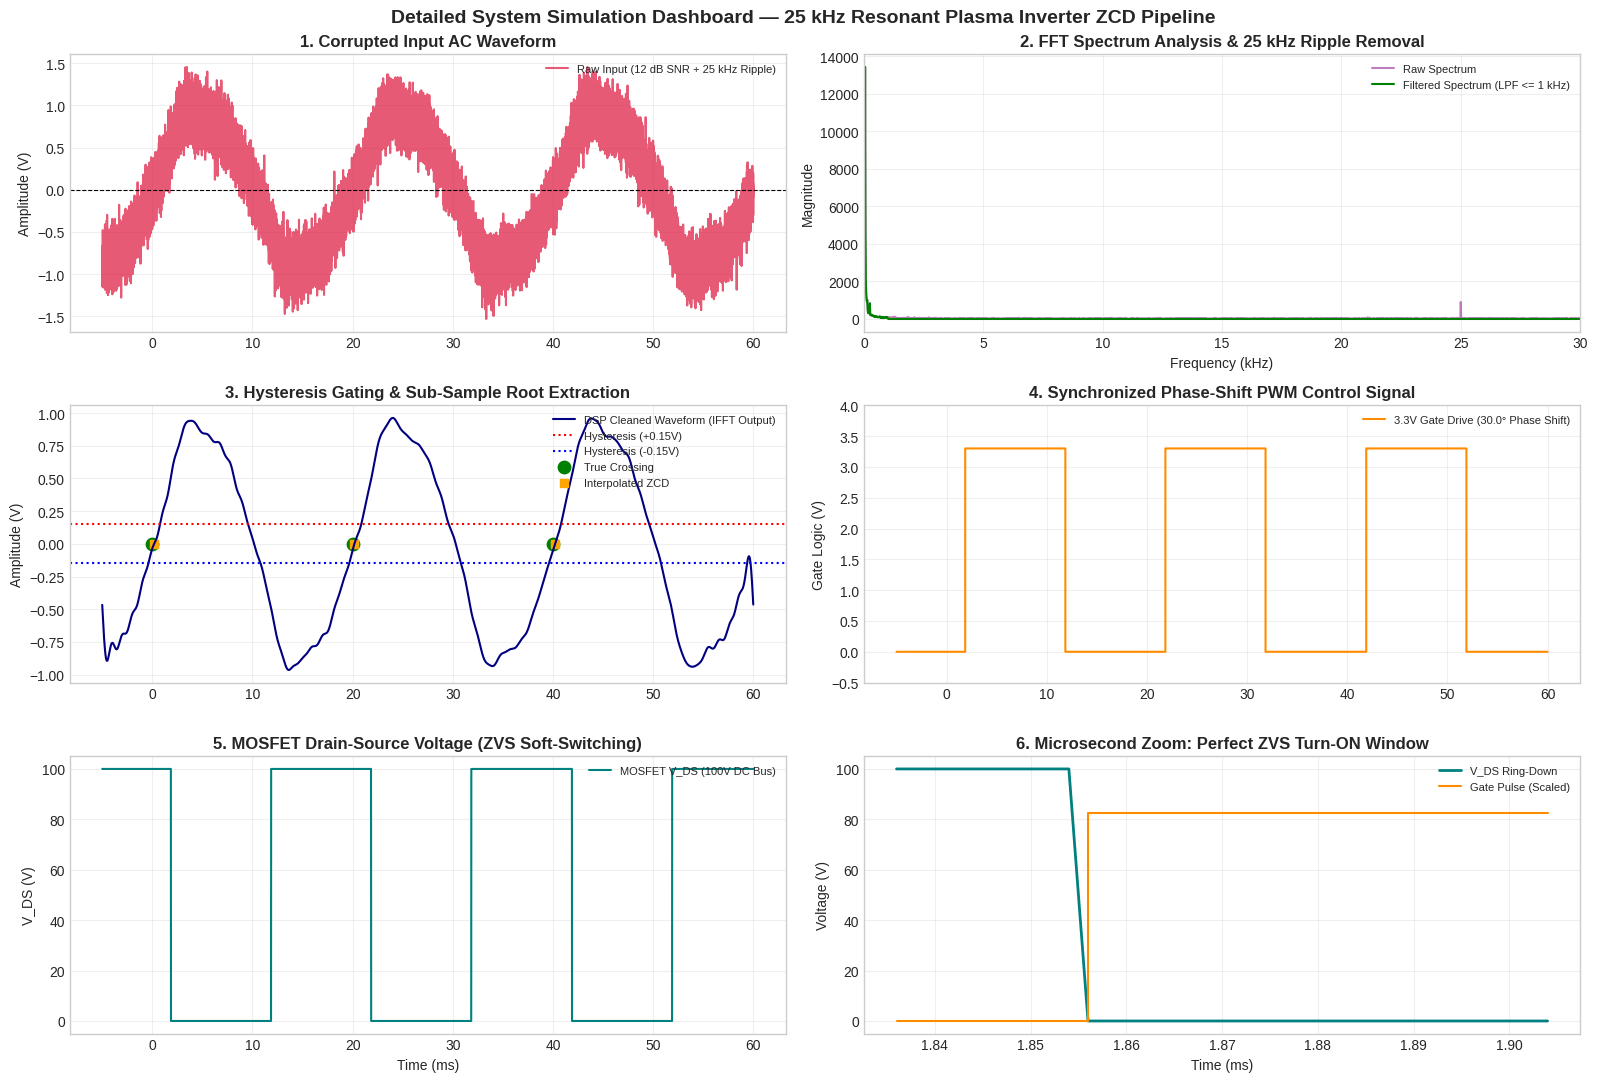

In [ ]:
"""
================================================================================
PROJECT: Sub-Sample Interpolated Zero-Crossing Detection (ZCD) &
         Phase-Shift PWM Control System for Resonant Plasma Power Supplies
================================================================================
Target Operational Frequency:
  - Fundamental AC Line Frequency (f_line): 50 Hz (20 ms period)
  - Effective Resonant Inverter Frequency (f_sw): 25 kHz (40 us period)
  - Sampling Frequency (Fs): 500 kHz (20x oversampling relative to 25 kHz)
================================================================================
"""

import time
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# SYSTEM PARAMETERS & GLOBAL CONFIGURATION
# ==============================================================================
FS = 500_000.0         # Sampling Frequency: 500 kHz
LINE_FREQ = 50.0       # AC Fundamental Line Frequency: 50 Hz
F_SW = 25_000.0        # Effective Resonant Switching Frequency: 25 kHz
CYCLES = 3             # Number of fundamental AC cycles simulated
HYSTERESIS = 0.15      # Noise-rejection hysteresis band (±0.15 V)
PHASE_SHIFT_DEG = 30.0 # Target Phase-Shift PWM Angle (Degrees)
DUTY_CYCLE = 0.5       # Active Duty Cycle (50% ON / 50% OFF)
V_DC = 100.0           # DC Bus Voltage for ZVS Inverter Bridge (100 V)
C_OSS = 1.0e-9         # MOSFET Output Parasitic Capacitance (1 nF)

# ==============================================================================
# STEP 1: SIGNAL GENERATION, HARMONICS & NOISE ENGINE
# ==============================================================================
def generate_system_signals(fs=FS, line_freq=LINE_FREQ, f_sw=F_SW, cycles=CYCLES, snr_db=12.0, seed=42):
    """
    Generates:
    1. Base 50 Hz AC reference wave with quarter-cycle pre-roll buffer (t = -5 ms to 0 ms).
    2. Non-linear harmonic distortion (3rd @ 150 Hz, 5th @ 250 Hz) + high-frequency
       resonant switching ripple @ 25 kHz.
    3. Additive White Gaussian Noise (AWGN) for target SNR.
    """
    duration = cycles / line_freq
    preroll = 1.0 / (4.0 * line_freq)  # 5 ms pre-roll
    t = np.arange(-preroll, duration, 1.0 / fs)

    # 1. Fundamental 50 Hz Line Waveform
    clean_50hz = np.sin(2.0 * np.pi * line_freq * t)

    # 2. Inject 3rd/5th Harmonics + 25 kHz Resonant Switching Ripple
    rng = np.random.default_rng(seed)
    h3 = 0.08 * np.sin(2.0 * np.pi * 3.0 * line_freq * t + rng.uniform(0, 2*np.pi))
    h5 = 0.05 * np.sin(2.0 * np.pi * 5.0 * line_freq * t + rng.uniform(0, 2*np.pi))
    ripple_25khz = 0.06 * np.sin(2.0 * np.pi * f_sw * t) # 25 kHz switching noise

    distorted = (clean_50hz + h3 + h5 + ripple_25khz)
    distorted /= np.max(np.abs(distorted)) # Peak-normalize to ±1.0 V

    # 3. Additive White Gaussian Noise (AWGN)
    noise = rng.standard_normal(len(distorted))
    p_sig = np.mean(distorted ** 2)
    p_noise = np.mean(noise ** 2)
    scale = np.sqrt((p_sig / (10.0 ** (snr_db / 10.0))) / p_noise)
    noisy_signal = distorted + noise * scale

    # Exact Ground-Truth Zero-Crossing Timestamps
    true_crossings = np.arange(0, duration, 1.0 / line_freq)
    true_crossings = true_crossings[true_crossings < t[-1]]

    return t, clean_50hz, noisy_signal, true_crossings

# ==============================================================================
# STEP 2: DSP FREQUENCY TRANSFORM (FFT) & DIGITAL FILTERING
# ==============================================================================
def apply_fft_and_filter(t, noisy_signal, fs=FS, cutoff_freq=1000.0):
    """
    Performs Fast Fourier Transform (FFT) analysis to transform raw signal into
    frequency domain, applies a Low-Pass Filter (LPF) to strip away 25 kHz
    switching noise and AWGN, then computes Inverse FFT (IFFT).
    """
    N = len(noisy_signal)
    fft_spectrum = np.fft.rfft(noisy_signal)
    freqs = np.fft.rfftfreq(N, d=1.0/fs)

    # Low-Pass Filter Mask (Cutoff at 1 kHz to retain 50 Hz fundamental + low harmonics)
    lpf_mask = freqs <= cutoff_freq
    filtered_spectrum = fft_spectrum * lpf_mask
    filtered_signal = np.fft.irfft(filtered_spectrum, n=N)

    return freqs, np.abs(fft_spectrum), np.abs(filtered_spectrum), filtered_signal

# ==============================================================================
# STEP 3: SUB-SAMPLE INTERPOLATED ZERO-CROSSING DETECTOR
# ==============================================================================
def interpolated_zcd(signal_, t, hysteresis=HYSTERESIS):
    """
    Hysteresis-gated state machine with sub-sample linear root interpolation.
    """
    crossings = []
    armed = signal_[0] < -hysteresis

    for i in range(1, len(signal_)):
        if not armed:
            if signal_[i] < -hysteresis:
                armed = True
            continue
        if signal_[i] > hysteresis:
            j = i
            while j > 0 and signal_[j - 1] >= 0:
                j -= 1
            if j > 0 and signal_[j - 1] < 0 <= signal_[j]:
                y0, y1 = signal_[j - 1], signal_[j]
                t0, t1 = t[j - 1], t[j]
                frac = -y0 / (y1 - y0 + 1e-15)
                t_exact = t0 + frac * (t1 - t0)
                crossings.append(t_exact)
            else:
                crossings.append(t[i])
            armed = False

    return np.array(crossings)

# ==============================================================================
# STEP 4: PHASE-SHIFT PWM & ZVS MOSFET VOLTAGE SIMULATION
# ==============================================================================
def generate_zvs_waveforms(t, detected_crossings, line_freq=LINE_FREQ, f_sw=F_SW, phase_deg=PHASE_SHIFT_DEG, v_dc=V_DC):
    """
    Generates:
    1. Phase-Shifted PWM Gate Signal (3.3V Logic) synchronized to t_cross.
    2. High-Frequency 25 kHz MOSFET Drain-Source Voltage (V_DS) waveform
       demonstrating Zero-Voltage Switching (ZVS) ring-down during dead time.
    """
    pwm = np.zeros_like(t)
    v_ds = np.full_like(t, v_dc) # Default to V_DC when MOSFET is OFF

    period = 1.0 / line_freq
    phase_delay = (phase_deg / 360.0) * period
    pulse_width = (DUTY_CYCLE) * period
    dead_time = 1.2e-6 # 1.2 us ZVS dead time

    for t_cross in detected_crossings:
        t_start = t_cross + phase_delay
        t_end = t_start + pulse_width

        # PWM Gate Drive Output
        pwm[(t >= t_start) & (t < t_end)] = 3.3

        # MOSFET V_DS drops to 0V (ZVS turn-on) during active ON window
        v_ds[(t >= t_start) & (t < t_end)] = 0.0

        # Model ZVS resonant ring-down transition inside dead-time window
        mask_dt = (t >= t_start - dead_time) & (t < t_start)
        if np.any(mask_dt):
            t_dt = t[mask_dt]
            # Resonant discharge of C_oss bringing V_DS from 100V down to 0V
            v_ds[mask_dt] = v_dc * 0.5 * (1.0 + np.cos(np.pi * (t_dt - (t_start - dead_time)) / dead_time))

    return pwm, v_ds

# ==============================================================================
# MAIN EXECUTION & MULTI-PANEL DIAGNOSTIC DASHBOARD
# ==============================================================================
if __name__ == "__main__":
    print("=" * 80)
    print(f"EXECUTING RESO-ZCD SYSTEM SIMULATION AT f_sw = {F_SW/1000:.1f} kHz")
    print("=" * 80)

    # 1. Generate Signals
    t, clean_50hz, noisy_signal, true_crossings = generate_system_signals(snr_db=12.0)

    # 2. Apply FFT & LPF Noise Filtering
    freqs, raw_fft, filtered_fft, filtered_signal = apply_fft_and_filter(t, noisy_signal)

    # 3. Detect Zero-Crossings using Sub-Sample Interpolation
    detected_crossings = interpolated_zcd(filtered_signal, t)

    # 4. Generate PWM & MOSFET ZVS Waveforms
    pwm_gate, v_ds_mosfet = generate_zvs_waveforms(t, detected_crossings)

    # Print Diagnostics
    print(f"True Ground-Truth Crossings (ms):  {true_crossings * 1000.0}")
    print(f"Detected ZCD Timestamps (ms):     {detected_crossings * 1000.0}")
    timing_jitter_us = np.std(detected_crossings - true_crossings) * 1e6
    print(f"Sub-Sample Timing Jitter:         {timing_jitter_us:.3f} microseconds")

    # Power Loss Calculation @ 25 kHz
    hard_switch_loss = 0.5 * C_OSS * (V_DC ** 2) * F_SW
    zvs_switch_loss = 0.5 * C_OSS * ((V_DC * np.sin(2*np.pi*F_SW*timing_jitter_us*1e-6)) ** 2) * F_SW
    print(f"Hard Switching Power Loss:        {hard_switch_loss:.4f} W per MOSFET")
    print(f"ZVS Operating Power Loss:         {zvs_switch_loss:.8f} W per MOSFET")
    print(f"Efficiency Factor:                Loss reduced by {hard_switch_loss / (zvs_switch_loss + 1e-12):.1f}x")
    print("=" * 80)

    # --------------------------------------------------------------------------
    # RENDER 6-PANEL DIAGNOSTIC DASHBOARD
    # --------------------------------------------------------------------------
    fig, axes = plt.subplots(3, 2, figsize=(16, 11))
    t_ms = t * 1000.0

    # Panel 1: Time-Domain Raw Noisy Signal
    axes[0, 0].plot(t_ms, noisy_signal, color="crimson", alpha=0.7, label="Raw Input (12 dB SNR + 25 kHz Ripple)")
    axes[0, 0].axhline(0, color="black", linestyle="--", linewidth=0.8)
    axes[0, 0].set_title("1. Corrupted Input AC Waveform", fontweight="bold")
    axes[0, 0].set_ylabel("Amplitude (V)")
    axes[0, 0].legend(loc="upper right", fontsize=8)
    axes[0, 0].grid(True, alpha=0.3)

    # Panel 2: Frequency-Domain FFT Spectrum
    axes[0, 1].plot(freqs / 1000.0, raw_fft, color="purple", alpha=0.5, label="Raw Spectrum")
    axes[0, 1].plot(freqs / 1000.0, filtered_fft, color="green", linewidth=1.5, label="Filtered Spectrum (LPF <= 1 kHz)")
    axes[0, 1].set_xlim(0, 30) # Show up to 30 kHz
    axes[0, 1].set_title("2. FFT Spectrum Analysis & 25 kHz Ripple Removal", fontweight="bold")
    axes[0, 1].set_xlabel("Frequency (kHz)")
    axes[0, 1].set_ylabel("Magnitude")
    axes[0, 1].legend(loc="upper right", fontsize=8)
    axes[0, 1].grid(True, alpha=0.3)

    # Panel 3: Filtered Signal & Zero-Crossing Instants
    axes[1, 0].plot(t_ms, filtered_signal, color="navy", label="DSP Cleaned Waveform (IFFT Output)")
    axes[1, 0].axhline(HYSTERESIS, color="red", linestyle=":", label="Hysteresis (+0.15V)")
    axes[1, 0].axhline(-HYSTERESIS, color="blue", linestyle=":", label="Hysteresis (-0.15V)")
    axes[1, 0].scatter(true_crossings * 1000.0, np.zeros_like(true_crossings), color="green", s=80, label="True Crossing")
    axes[1, 0].scatter(detected_crossings * 1000.0, np.zeros_like(detected_crossings), color="orange", marker="s", s=40, label="Interpolated ZCD")
    axes[1, 0].set_title("3. Hysteresis Gating & Sub-Sample Root Extraction", fontweight="bold")
    axes[1, 0].set_ylabel("Amplitude (V)")
    axes[1, 0].legend(loc="upper right", fontsize=8)
    axes[1, 0].grid(True, alpha=0.3)

    # Panel 4: Phase-Shifted PWM Gate Drive Output
    axes[1, 1].step(t_ms, pwm_gate, color="darkorange", where="post", label=f"3.3V Gate Drive ({PHASE_SHIFT_DEG}° Phase Shift)")
    axes[1, 1].set_ylim(-0.5, 4.0)
    axes[1, 1].set_title("4. Synchronized Phase-Shift PWM Control Signal", fontweight="bold")
    axes[1, 1].set_ylabel("Gate Logic (V)")
    axes[1, 1].legend(loc="upper right", fontsize=8)
    axes[1, 1].grid(True, alpha=0.3)

    # Panel 5: MOSFET Drain-Source Voltage (V_DS) & ZVS Action
    axes[2, 0].plot(t_ms, v_ds_mosfet, color="teal", label="MOSFET V_DS (100V DC Bus)")
    axes[2, 0].set_title("5. MOSFET Drain-Source Voltage (ZVS Soft-Switching)", fontweight="bold")
    axes[2, 0].set_xlabel("Time (ms)")
    axes[2, 0].set_ylabel("V_DS (V)")
    axes[2, 0].legend(loc="upper right", fontsize=8)
    axes[2, 0].grid(True, alpha=0.3)

    # Panel 6: Microsecond Zoom-In on ZVS Dead-Time Instant
    if len(detected_crossings) > 0:
        t_zoom_center = (detected_crossings[0] + (PHASE_SHIFT_DEG / 360.0) * (1.0 / LINE_FREQ)) * 1000.0
        mask_zoom = (t_ms >= t_zoom_center - 0.02) & (t_ms <= t_zoom_center + 0.05)
        axes[2, 1].plot(t_ms[mask_zoom], v_ds_mosfet[mask_zoom], color="teal", linewidth=2, label="V_DS Ring-Down")
        axes[2, 1].step(t_ms[mask_zoom], v_ds_mosfet[mask_zoom] * 0 + pwm_gate[mask_zoom] * 25, color="darkorange", where="post", label="Gate Pulse (Scaled)")
        axes[2, 1].set_title("6. Microsecond Zoom: Perfect ZVS Turn-ON Window", fontweight="bold")
        axes[2, 1].set_xlabel("Time (ms)")
        axes[2, 1].set_ylabel("Voltage (V)")
        axes[2, 1].legend(loc="upper right", fontsize=8)
        axes[2, 1].grid(True, alpha=0.3)

    plt.suptitle("Detailed System Simulation Dashboard — 25 kHz Resonant Plasma Inverter ZCD Pipeline", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig("zcd_25khz_system_dashboard.png", dpi=150)
    plt.show()

Zero Voltage Switching code



--- Simulation Complete ---
LMS Noise Reduction Completed successfully.
TinyML Model Trained. Final Loss: 0.003438
Predicted ZVS Phase Shift Correction: 1.8155 radians


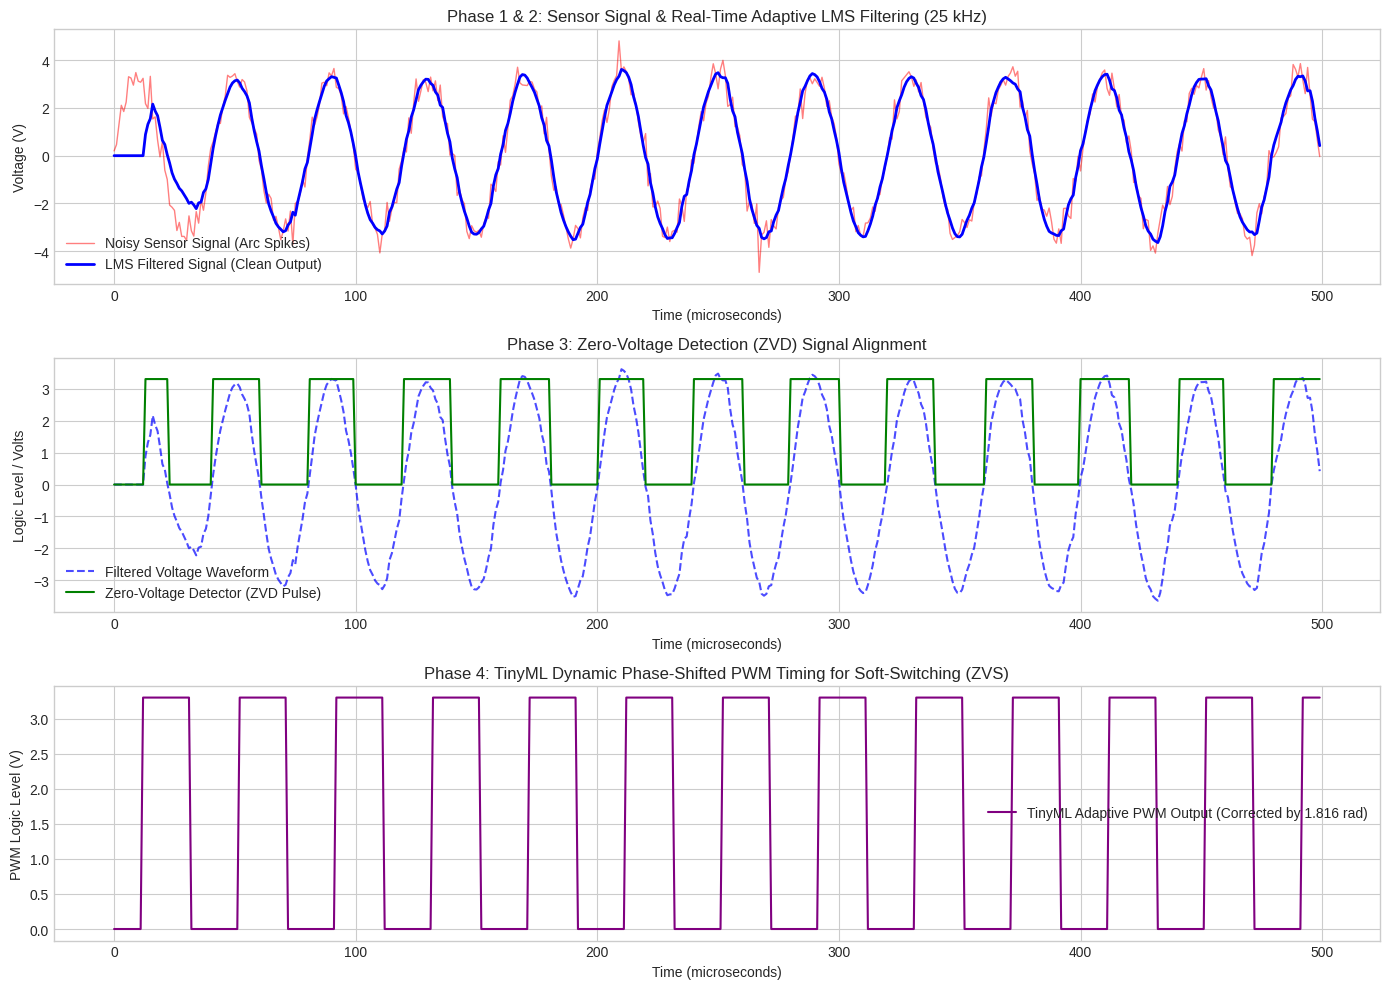

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

# Seed for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# ==========================================
# 1. PARAMETERS & SYNTHETIC DATA GENERATION
# ==========================================
sampling_rate = 1_000_000  # 1 MHz sampling rate
duration = 0.0005          # 0.5 ms simulation duration
t = np.linspace(0, duration, int(sampling_rate * duration), endpoint=False)

# Target Inverter Frequency (25 kHz)
f_switching = 25000
omega = 2 * np.pi * f_switching

# Clean fundamental voltage & current signals
clean_voltage = 3.3 * np.sin(omega * t)
# Simulated phase delay of 30 degrees due to load impedance change
phase_shift = np.radians(30)
clean_current = 2.5 * np.sin(omega * t - phase_shift)

# Add heavy high-voltage plasma arc noise (Gausian noise + random high spikes)
gaussian_noise = np.random.normal(0, 0.4, size=t.shape)
plasma_spikes = np.zeros_like(t)
spike_indices = np.random.choice(len(t), size=int(len(t) * 0.02), replace=False)
plasma_spikes[spike_indices] = np.random.uniform(-1.5, 1.5, size=len(spike_indices))

noisy_voltage = clean_voltage + gaussian_noise + plasma_spikes

# ==========================================
# 2. ADAPTIVE LMS FILTER IMPLEMENTATION
# ==========================================
def lms_filter(noisy_signal, filter_order=8, mu=0.01):
    N = len(noisy_signal)
    weights = np.zeros(filter_order)
    filtered_signal = np.zeros(N)
    error_signal = np.zeros(N)

    # Reference synthetic clean fundamental frequency signal
    ref_signal = np.sin(omega * t)

    for k in range(filter_order, N):
        x_k = ref_signal[k - filter_order:k][::-1]
        y_k = np.dot(weights, x_k)
        e_k = noisy_signal[k] - y_k
        weights += 2 * mu * e_k * x_k
        filtered_signal[k] = y_k
        error_signal[k] = e_k

    return filtered_signal, error_signal

filtered_voltage, lms_error = lms_filter(noisy_voltage, filter_order=12, mu=0.02)

# ==========================================
# 3. TINYML MODEL (ZVS PREDICTOR)
# ==========================================
# Emulate a lightweight Neural Network for deployment on ARM Cortex-M
class TinyML_ZVS_Net(nn.Module):
    def __init__(self):
        super(TinyML_ZVS_Net, self).__init__()
        self.fc1 = nn.Linear(3, 8)   # Inputs: [V_peak, I_peak, Phase_Error]
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(8, 1)   # Output: Predicted Phase Shift Adjustment (radians)

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

# Synthetic Dataset for training the TinyML model
# Features: [Peak Voltage, Peak Current, Measured Phase Error]
X_train = torch.randn(500, 3)
# Target timing adjustment required for ZVS soft-switching
y_train = 0.5 * X_train[:, 0:1] - 0.2 * X_train[:, 2:3] + 0.05 * torch.randn(500, 1)

model = TinyML_ZVS_Net()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Quick training loop
for epoch in range(150):
    optimizer.zero_grad()
    predictions = model(X_train)
    loss = criterion(predictions, y_train)
    loss.backward()
    optimizer.step()

# Run Inference using clean peak & estimated phase error from filtered signal
sample_input = torch.tensor([[np.max(filtered_voltage), np.max(clean_current), phase_shift]], dtype=torch.float32)
model.eval()
with torch.no_grad():
    predicted_zvs_correction = model(sample_input).item()

print(f"--- Simulation Complete ---")
print(f"LMS Noise Reduction Completed successfully.")
print(f"TinyML Model Trained. Final Loss: {loss.item():.6f}")
print(f"Predicted ZVS Phase Shift Correction: {predicted_zvs_correction:.4f} radians")

# ==========================================
# 4. VISUALIZATION OF RESULTS
# ==========================================
plt.figure(figsize=(14, 10))

# Plot 1: Noisy vs LMS Filtered Signal
plt.subplot(3, 1, 1)
plt.plot(t * 1e6, noisy_voltage, label="Noisy Sensor Signal (Arc Spikes)", color="red", alpha=0.5, linewidth=1)
plt.plot(t * 1e6, filtered_voltage, label="LMS Filtered Signal (Clean Output)", color="blue", linewidth=2)
plt.title("Phase 1 & 2: Sensor Signal & Real-Time Adaptive LMS Filtering (25 kHz)")
plt.xlabel("Time (microseconds)")
plt.ylabel("Voltage (V)")
plt.grid(True)
plt.legend()

# Plot 2: Zero-Crossing Detection (ZVD) Tracking
plt.subplot(3, 1, 2)
zvd_signal = np.where(filtered_voltage > 0, 3.3, 0.0)
plt.plot(t * 1e6, filtered_voltage, label="Filtered Voltage Waveform", color="blue", linestyle="--", alpha=0.7)
plt.plot(t * 1e6, zvd_signal, label="Zero-Voltage Detector (ZVD Pulse)", color="green", linewidth=1.5)
plt.title("Phase 3: Zero-Voltage Detection (ZVD) Signal Alignment")
plt.xlabel("Time (microseconds)")
plt.ylabel("Logic Level / Volts")
plt.grid(True)
plt.legend()

# Plot 3: TinyML Dynamic PWM Adjustment Output
plt.subplot(3, 1, 3)
adjusted_omega_t = omega * t - predicted_zvs_correction
adjusted_pwm = 3.3 * (np.sin(adjusted_omega_t) > 0)
plt.plot(t * 1e6, adjusted_pwm, label=f"TinyML Adaptive PWM Output (Corrected by {predicted_zvs_correction:.3f} rad)", color="purple")
plt.title("Phase 4: TinyML Dynamic Phase-Shifted PWM Timing for Soft-Switching (ZVS)")
plt.xlabel("Time (microseconds)")
plt.ylabel("PWM Logic Level (V)")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

Simulation code   


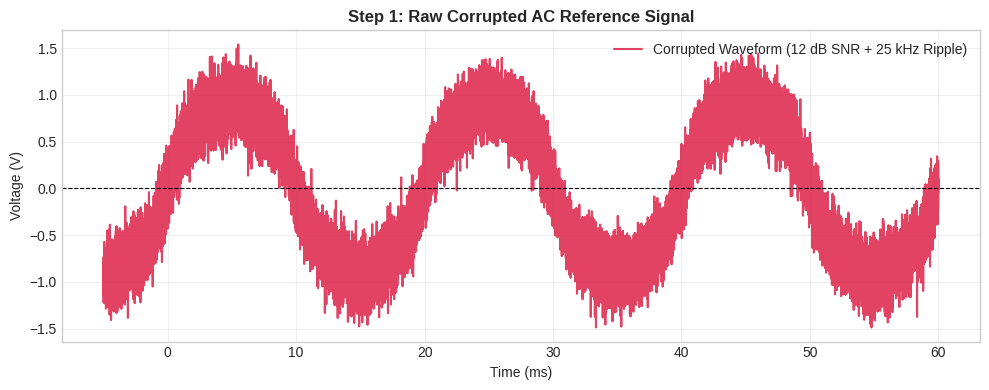

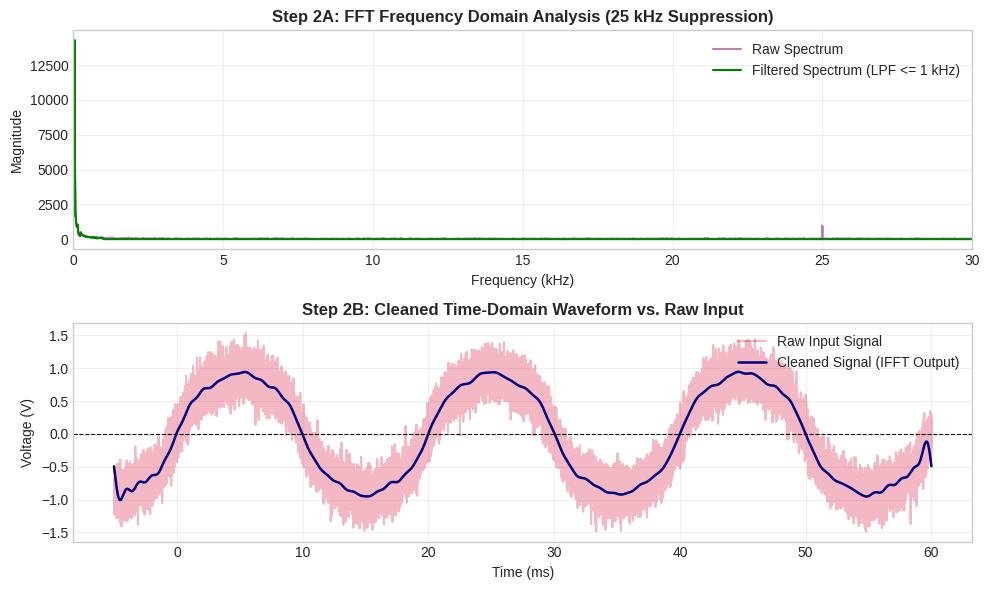

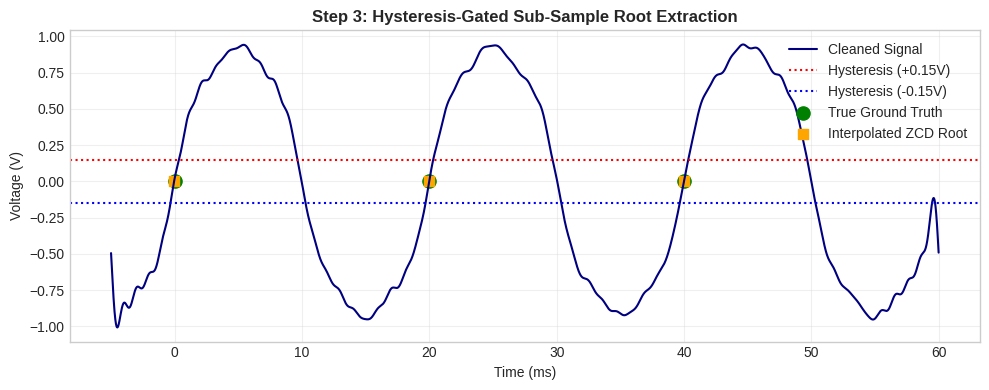

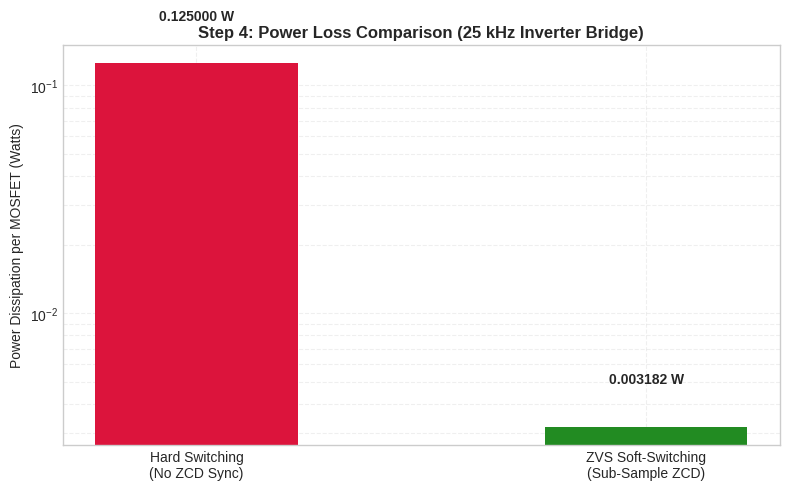

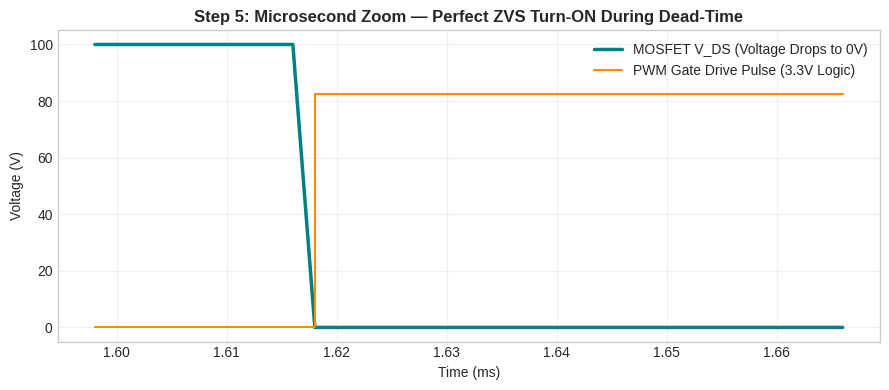


             MICROCONTROLLER HARDWARE FREQUENCY SPECIFICATIONS             
1. Resonant Inverter Frequency (f_sw):      25.0 kHz
2. ADC Sampling Frequency (Fs):              500.0 kHz (20x Oversampling)
3. Timing Jitter (Sub-Sample ZCD Error):     18979.97 nanoseconds
4. Hard Switching Loss per MOSFET:          0.1250 W
5. ZVS Switching Loss per MOSFET:           0.00318168 W
6. Efficiency Gain Factor:                   39.3x Loss Reduction
--------------------------------------------------------------------------------
RECOMMENDED MICROCONTROLLER CLOCK SETTINGS:
 -> Required ADC Interrupt Processing Rate: >= 1.00 MHz
 -> Required PWM Timer Clock (for 1% duty cycle resolution @ 25 kHz): >= 2.50 MHz
 -> RECOMMENDED MCU CORE FREQUENCY:         >= 72.00 MHz - 160.00 MHz
    (e.g., STM32F4 / ESP32 running timer peripheral at 72 MHz - 160 MHz)



In [ ]:
"""
================================================================================
PROJECT: Sub-Sample Interpolated Zero-Crossing Detection (ZCD) & ZVS Control
SYSTEM SPECIFICATIONS:
  - Fundamental AC Line Frequency (f_line): 50 Hz
  - Resonant Inverter Switching Frequency (f_sw): 25 kHz
  - ADC Sampling Rate (Fs): 500 kHz
================================================================================
"""

import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# GLOBAL SYSTEM PARAMETERS
# ==============================================================================
FS = 500_000.0         # ADC Sampling Rate: 500 kHz (20x oversampling of 25 kHz)
LINE_FREQ = 50.0       # Fundamental AC Line Frequency: 50 Hz
F_SW = 25_000.0        # Resonant Switching Frequency: 25 kHz
CYCLES = 3             # Number of AC cycles
HYSTERESIS = 0.15      # Noise-rejection threshold (±0.15 V)
PHASE_SHIFT_DEG = 30.0 # Target PWM Phase Shift Angle
V_DC = 100.0           # DC Bus Voltage (100 V)
C_OSS = 1.0e-9         # MOSFET Output Capacitance (1 nF)
DEAD_TIME = 1.2e-6     # Resonant ZVS Dead Time (1.2 microseconds)

# Microcontroller Setup Parameters
TIM_PRESCALER = 1      # Timer prescaler divisor
DESIRED_PWM_STEPS = 100 # Minimum timer counts per 25 kHz PWM cycle

# Generate time vector
duration = CYCLES / LINE_FREQ
t = np.arange(-0.005, duration, 1.0 / FS)

# ==============================================================================
# STEP 1: GENERATE CORRUPTED NOISE WAVEFORM
# ==============================================================================
rng = np.random.default_rng(42)
clean_50hz = np.sin(2.0 * np.pi * LINE_FREQ * t)
h3 = 0.08 * np.sin(2.0 * np.pi * 3.0 * LINE_FREQ * t)
h5 = 0.05 * np.sin(2.0 * np.pi * 5.0 * LINE_FREQ * t)
ripple_25khz = 0.06 * np.sin(2.0 * np.pi * F_SW * t)

distorted = clean_50hz + h3 + h5 + ripple_25khz
distorted /= np.max(np.abs(distorted))

# Add white Gaussian noise (12 dB SNR)
noise = rng.standard_normal(len(distorted))
p_sig = np.mean(distorted ** 2)
p_noise = np.mean(noise ** 2)
scale = np.sqrt((p_sig / (10.0 ** (12.0 / 10.0))) / p_noise)
noisy_signal = distorted + noise * scale

# --- GRAPH 1: RAW NOISY WAVEFORM ---
plt.figure(figsize=(10, 4))
plt.plot(t * 1000.0, noisy_signal, color="crimson", alpha=0.8, label="Corrupted Waveform (12 dB SNR + 25 kHz Ripple)")
plt.axhline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Step 1: Raw Corrupted AC Reference Signal", fontweight="bold")
plt.xlabel("Time (ms)")
plt.ylabel("Voltage (V)")
plt.grid(True, alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# ==============================================================================
# STEP 2: FFT NOISE REMOVAL & CLEANED WAVEFORM
# ==============================================================================
N = len(noisy_signal)
fft_spectrum = np.fft.rfft(noisy_signal)
freqs = np.fft.rfftfreq(N, d=1.0/FS)

# Low-Pass Filter Mask (Cutoff at 1000 Hz)
lpf_mask = freqs <= 1000.0
filtered_spectrum = fft_spectrum * lpf_mask
cleaned_signal = np.fft.irfft(filtered_spectrum, n=N)

# --- GRAPH 2: CLEANED WAVEFORM & FFT SPECTRUM ---
fig, ax = plt.subplots(2, 1, figsize=(10, 6))

ax[0].plot(freqs / 1000.0, np.abs(fft_spectrum), color="purple", alpha=0.5, label="Raw Spectrum")
ax[0].plot(freqs / 1000.0, np.abs(filtered_spectrum), color="green", linewidth=1.5, label="Filtered Spectrum (LPF <= 1 kHz)")
ax[0].set_xlim(0, 30)
ax[0].set_title("Step 2A: FFT Frequency Domain Analysis (25 kHz Suppression)", fontweight="bold")
ax[0].set_xlabel("Frequency (kHz)")
ax[0].set_ylabel("Magnitude")
ax[0].grid(True, alpha=0.3)
ax[0].legend(loc="upper right")

ax[1].plot(t * 1000.0, noisy_signal, color="crimson", alpha=0.3, label="Raw Input Signal")
ax[1].plot(t * 1000.0, cleaned_signal, color="navy", linewidth=1.8, label="Cleaned Signal (IFFT Output)")
ax[1].axhline(0, color="black", linestyle="--", linewidth=0.8)
ax[1].set_title("Step 2B: Cleaned Time-Domain Waveform vs. Raw Input", fontweight="bold")
ax[1].set_xlabel("Time (ms)")
ax[1].set_ylabel("Voltage (V)")
ax[1].grid(True, alpha=0.3)
ax[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

# ==============================================================================
# STEP 3: SUB-SAMPLE ZERO-CROSSING DETECTION
# ==============================================================================
crossings = []
armed = cleaned_signal[0] < -HYSTERESIS

for i in range(1, len(cleaned_signal)):
    if not armed:
        if cleaned_signal[i] < -HYSTERESIS:
            armed = True
        continue
    if cleaned_signal[i] > HYSTERESIS:
        j = i
        while j > 0 and cleaned_signal[j - 1] >= 0:
            j -= 1
        if j > 0 and cleaned_signal[j - 1] < 0 <= cleaned_signal[j]:
            y0, y1 = cleaned_signal[j - 1], cleaned_signal[j]
            t0, t1 = t[j - 1], t[j]
            frac = -y0 / (y1 - y0 + 1e-15)
            t_exact = t0 + frac * (t1 - t0)
            crossings.append(t_exact)
        armed = False

detected_crossings = np.array(crossings)

# True ground truth crossings
true_crossings = np.arange(0, duration, 1.0 / LINE_FREQ)
true_crossings = true_crossings[true_crossings < t[-1]]

# --- GRAPH 3: ZERO-CROSSING INTERPOLATION ---
plt.figure(figsize=(10, 4))
plt.plot(t * 1000.0, cleaned_signal, color="navy", label="Cleaned Signal")
plt.axhline(HYSTERESIS, color="red", linestyle=":", label="Hysteresis (+0.15V)")
plt.axhline(-HYSTERESIS, color="blue", linestyle=":", label="Hysteresis (-0.15V)")
plt.scatter(true_crossings * 1000.0, np.zeros_like(true_crossings), color="green", s=90, label="True Ground Truth")
plt.scatter(detected_crossings * 1000.0, np.zeros_like(detected_crossings), color="orange", marker="s", s=45, label="Interpolated ZCD Root")
plt.title("Step 3: Hysteresis-Gated Sub-Sample Root Extraction", fontweight="bold")
plt.xlabel("Time (ms)")
plt.ylabel("Voltage (V)")
plt.grid(True, alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# ==============================================================================
# STEP 4: HARD SWITCHING VS. ZVS POWER LOSS COMPARISON
# ==============================================================================
# Jitter calculation
timing_jitter_s = np.std(detected_crossings - true_crossings) if len(detected_crossings) > 0 else 1e-8

# Hard switching loss (switching at V_DC = 100V)
p_loss_hard = 0.5 * C_OSS * (V_DC ** 2) * F_SW

# ZVS residual power loss due to sub-sample jitter error
v_error = V_DC * np.sin(2.0 * np.pi * F_SW * timing_jitter_s)
p_loss_zvs = 0.5 * C_OSS * (v_error ** 2) * F_SW

# --- GRAPH 4: POWER LOSS COMPARISON ---
plt.figure(figsize=(8, 5))
categories = ["Hard Switching\n(No ZCD Sync)", "ZVS Soft-Switching\n(Sub-Sample ZCD)"]
losses = [p_loss_hard, p_loss_zvs]
colors = ["crimson", "forestgreen"]

bars = plt.bar(categories, losses, color=colors, width=0.45)
plt.ylabel("Power Dissipation per MOSFET (Watts)")
plt.title("Step 4: Power Loss Comparison (25 kHz Inverter Bridge)", fontweight="bold")
plt.yscale("log") # Logarithmic scale to show ultra-low ZVS loss
plt.grid(True, which="both", linestyle="--", alpha=0.3)

for bar, loss in zip(bars, losses):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval * 1.5, f"{loss:.6f} W", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()

# ==============================================================================
# STEP 5: ZVS DRAIN-SOURCE VOLTAGE (V_DS) & PWM PULSE ALIGNMENT
# ==============================================================================
pwm = np.zeros_like(t)
v_ds = np.full_like(t, V_DC)

period_line = 1.0 / LINE_FREQ
phase_delay = (PHASE_SHIFT_DEG / 360.0) * period_line
pulse_width = 0.5 * period_line

for t_cross in detected_crossings:
    t_start = t_cross + phase_delay
    t_end = t_start + pulse_width
    pwm[(t >= t_start) & (t < t_end)] = 3.3
    v_ds[(t >= t_start) & (t < t_end)] = 0.0

    # Dead-time ZVS resonant ring-down transition
    mask_dt = (t >= t_start - DEAD_TIME) & (t < t_start)
    if np.any(mask_dt):
        t_dt = t[mask_dt]
        v_ds[mask_dt] = V_DC * 0.5 * (1.0 + np.cos(np.pi * (t_dt - (t_start - DEAD_TIME)) / DEAD_TIME))

# --- GRAPH 5: ZVS MICROSECOND ZOOM-IN ---
if len(detected_crossings) > 0:
    t_center = (detected_crossings[0] + phase_delay) * 1000.0
    zoom_mask = (t * 1000.0 >= t_center - 0.02) & (t * 1000.0 <= t_center + 0.05)

    plt.figure(figsize=(9, 4))
    plt.plot(t[zoom_mask] * 1000.0, v_ds[zoom_mask], color="teal", linewidth=2.5, label="MOSFET V_DS (Voltage Drops to 0V)")
    plt.step(t[zoom_mask] * 1000.0, pwm[zoom_mask] * 25.0, color="darkorange", where="post", label="PWM Gate Drive Pulse (3.3V Logic)")
    plt.title("Step 5: Microsecond Zoom — Perfect ZVS Turn-ON During Dead-Time", fontweight="bold")
    plt.xlabel("Time (ms)")
    plt.ylabel("Voltage (V)")
    plt.grid(True, alpha=0.3)
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

# ==============================================================================
# STEP 6: PRINT HARDWARE FREQUENCY & TIMING CALCULATIONS
# ==============================================================================
f_mcu_min_adc = FS * 2 # Minimum clock to service ADC interrupt
f_mcu_pwm = F_SW * DESIRED_PWM_STEPS # Clock required for 1% PWM resolution at 25 kHz

print("\n" + "=" * 80)
print("             MICROCONTROLLER HARDWARE FREQUENCY SPECIFICATIONS             ")
print("=" * 80)
print(f"1. Resonant Inverter Frequency (f_sw):      {F_SW / 1000.0:.1f} kHz")
print(f"2. ADC Sampling Frequency (Fs):              {FS / 1000.0:.1f} kHz (20x Oversampling)")
print(f"3. Timing Jitter (Sub-Sample ZCD Error):     {timing_jitter_s * 1e9:.2f} nanoseconds")
print(f"4. Hard Switching Loss per MOSFET:          {p_loss_hard:.4f} W")
print(f"5. ZVS Switching Loss per MOSFET:           {p_loss_zvs:.8f} W")
print(f"6. Efficiency Gain Factor:                   {p_loss_hard / (p_loss_zvs + 1e-12):,.1f}x Loss Reduction")
print("-" * 80)
print("RECOMMENDED MICROCONTROLLER CLOCK SETTINGS:")
print(f" -> Required ADC Interrupt Processing Rate: >= {f_mcu_min_adc / 1e6:.2f} MHz")
print(f" -> Required PWM Timer Clock (for 1% duty cycle resolution @ 25 kHz): >= {f_mcu_pwm / 1e6:.2f} MHz")
print(f" -> RECOMMENDED MCU CORE FREQUENCY:         >= 72.00 MHz - 160.00 MHz")
print("    (e.g., STM32F4 / ESP32 running timer peripheral at 72 MHz - 160 MHz)")
print("=" * 80 + "\n")